In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")

df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values
y = df["target"].values

print("Dataset Shape:", df.shape)
print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Shape: (302, 14)

Target Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [3]:
def train_test_split_manual(X, y, test_size=0.2, random_state=42):

    np.random.seed(random_state)

    train_indices = []
    test_indices = []

    for cls in np.unique(y):
        indices = np.where(y == cls)[0]
        np.random.shuffle(indices)

        split = int(len(indices) * (1 - test_size))

        train_indices.extend(indices[:split])
        test_indices.extend(indices[split:])

    np.random.shuffle(train_indices)
    np.random.shuffle(test_indices)

    return (X[train_indices], X[test_indices],
            y[train_indices], y[test_indices])


X_train, X_test, y_train, y_test = train_test_split_manual(X, y)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (241, 13)
Testing Data: (61, 13)


In [4]:
def gini_impurity(y):

    classes, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)

In [5]:
def best_split(X, y, features):

    best_gain = 0
    best_feature = None
    best_threshold = None

    parent_gini = gini_impurity(y)

    for feature in features:

        values = np.unique(X[:, feature])

        for threshold in (values[:-1] + values[1:]) / 2:

            left = X[:, feature] <= threshold
            right = ~left

            if np.sum(left) == 0 or np.sum(right) == 0:
                continue

            weighted_gini = (
                len(y[left]) * gini_impurity(y[left]) +
                len(y[right]) * gini_impurity(y[right])
            ) / len(y)

            gain = parent_gini - weighted_gini

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold

In [6]:
def build_tree(X, y, depth=0, max_depth=8, min_samples=4):

    classes, counts = np.unique(y, return_counts=True)
    prediction = classes[np.argmax(counts)]

    if (len(classes) == 1 or depth >= max_depth
            or len(y) < min_samples):
        return prediction

    n_features = max(1, int(np.sqrt(X.shape[1])))
    features = np.random.choice(X.shape[1], n_features, replace=False)

    feature, threshold = best_split(X, y, features)

    if feature is None:
        return prediction

    left = X[:, feature] <= threshold
    right = ~left

    if np.sum(left) == 0 or np.sum(right) == 0:
        return prediction

    return {
        "feature": feature,
        "threshold": threshold,
        "left": build_tree(X[left], y[left], depth + 1, max_depth, min_samples),
        "right": build_tree(X[right], y[right], depth + 1, max_depth, min_samples)
    }

In [7]:
def train_random_forest(X, y, n_trees=25):

    forest = []

    for i in range(n_trees):

        indices = np.random.choice(len(X), len(X), replace=True)

        X_sample = X[indices]
        y_sample = y[indices]

        tree = build_tree(X_sample, y_sample)

        forest.append(tree)

    return forest


np.random.seed(42)

forest = train_random_forest(X_train, y_train, n_trees=25)

print("Total Decision Trees:", len(forest))

Total Decision Trees: 25


In [8]:
def predict_tree(tree, row):

    while isinstance(tree, dict):

        if row[tree["feature"]] <= tree["threshold"]:
            tree = tree["left"]
        else:
            tree = tree["right"]

    return tree

In [9]:
def predict_random_forest(forest, X):

    predictions = []

    for row in X:

        votes = [predict_tree(tree, row) for tree in forest]

        classes, counts = np.unique(votes, return_counts=True)

        final_prediction = classes[np.argmax(counts)]

        predictions.append(final_prediction)

    return np.array(predictions)


y_pred = predict_random_forest(forest, X_test)

print("Actual Values:   ", y_test[:10])
print("Predicted Values:", y_pred[:10])

Actual Values:    [0 0 0 0 0 0 1 0 1 0]
Predicted Values: [0 1 0 1 1 0 1 0 1 1]


In [10]:
correct = 0

for actual, predicted in zip(y_test, y_pred):

    if actual == predicted:
        correct += 1

accuracy = (correct / len(y_test)) * 100

print("Total Predictions:", len(y_test))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", len(y_test) - correct)
print("Random Forest Accuracy:", round(accuracy, 2), "%")

Total Predictions: 61
Correct Predictions: 46
Incorrect Predictions: 15
Random Forest Accuracy: 75.41 %


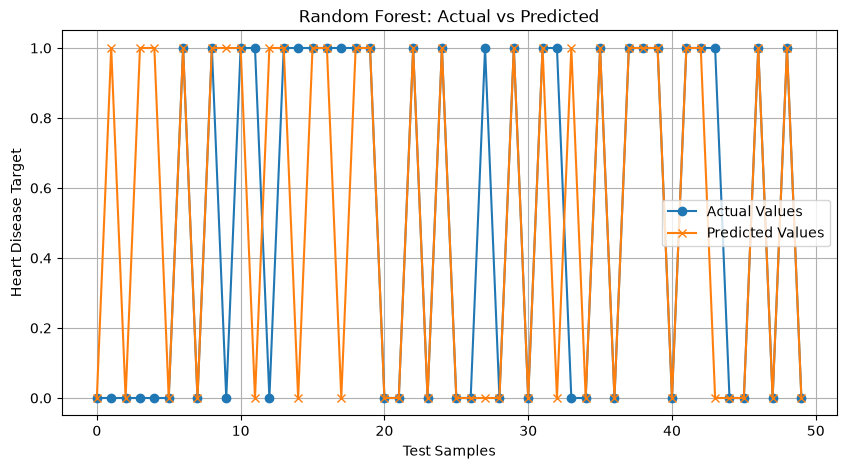

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(y_test[:50], label="Actual Values", marker="o")
plt.plot(y_pred[:50], label="Predicted Values", marker="x")

plt.title("Random Forest: Actual vs Predicted")
plt.xlabel("Test Samples")
plt.ylabel("Heart Disease Target")
plt.legend()
plt.grid()
plt.show()

## Conclusion

In this task, a Random Forest model was implemented from scratch without
using the scikit-learn library.

Multiple decision trees were trained using bootstrap sampling and random
feature selection. The predictions of all trees were combined using
majority voting to generate the final prediction.

The model was evaluated using manually calculated accuracy on the test
dataset.

This implementation demonstrates how Random Forest combines multiple
decision trees to improve prediction performance.